# 04 — Shared Baseline Modelling and OOF Evaluation

## Purpose

This notebook establishes simple reference performance levels before the six advanced headline models are trained.

The mandatory baselines are:
1. `DummyClassifier(strategy="prior")`
2. `DummyClassifier(strategy="most_frequent")`

All baseline evaluation uses:
- The frozen 80,000-row development partition;
- The exact five saved outer CV folds;
- One out-of-fold prediction per development record;
- The target orientation `Resigned=True` as positive.

To run This file you need to install these libraries.
- numpy
- pandas
- matplotlin.pyplot
- PyYAML
- sklearn

If you have not installed any libraries run this in this notebook.

`%pip install numpy pandas matplotlib pyyaml scikit-learn`

### IMPORT REQUIRED LIBRARIES AND DETECT PROJECT PATHS


In [1]:
from pathlib import Path
import hashlib
import math
import sys


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Project root detection
# ============================================================

current_path = Path.cwd().resolve()

if current_path.name == "notebooks":
    project_root = current_path.parent
else:
    project_root = current_path

# Allow notebook code to import modules from src/
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))


# ============================================================
# YAML
# ============================================================

try:
    import yaml
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "PyYAML is required for this notebook. "
        "Install it in the active environment with: pip install pyyaml"
    ) from exc


# ============================================================
# scikit-learn
# ============================================================

try:
    from sklearn.dummy import DummyClassifier
    from sklearn.metrics import (
        confusion_matrix,
        precision_recall_curve,
    )
    from sklearn.compose import ColumnTransformer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import OneHotEncoder, StandardScaler

except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "scikit-learn is required for the baseline notebook. "
        "Install it in the active environment with: pip install scikit-learn"
    ) from exc


# ============================================================
# Shared project evaluation utilities
# ============================================================

try:
    from src.evaluation.metrics import calculate_binary_metrics
    from src.evaluation.oof_validation import validate_oof_predictions

except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "Could not import the project's shared evaluation utilities. "
        "Make sure this notebook is being run from the project repository "
        "and that src/evaluation/metrics.py and "
        "src/evaluation/oof_validation.py exist."
    ) from exc


# ============================================================
# Display settings
# ============================================================

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)


print("Imports loaded successfully.")


Imports loaded successfully.


### LOAD AND VERIFY THE FROZEN FEATURE CONTRACT

In [2]:
# ============================================================
# Load and verify the frozen feature contract
# ============================================================

feature_contract_file = (
    project_root
    / "configs"
    / "feature_contract.yaml"
)


if not feature_contract_file.exists():
    raise FileNotFoundError(
        "Feature contract not found:\n"
        f"{feature_contract_file}"
    )


with feature_contract_file.open(
    "r",
    encoding="utf-8",
) as file:
    feature_contract = yaml.safe_load(file)


if not isinstance(feature_contract, dict):
    raise ValueError(
        "Feature contract could not be loaded as a valid YAML mapping."
    )


# ============================================================
# Contract status
# ============================================================

contract_status = feature_contract["contract"]["status"]

if contract_status != "frozen":
    raise ValueError(
        "Feature contract is not marked as frozen."
    )


# ============================================================
# Target contract
# ============================================================

target_column = feature_contract["target"]["column"]
positive_class = feature_contract["target"]["positive_class"]
negative_class = feature_contract["target"]["negative_class"]


if target_column != "Resigned":
    raise ValueError(
        f"Unexpected target column: {target_column}"
    )

if positive_class is not True:
    raise ValueError(
        "The positive class must be True."
    )

if negative_class is not False:
    raise ValueError(
        "The negative class must be False."
    )


# ============================================================
# Predictor contract
# ============================================================

categorical_features = [
    item["name"]
    for item in feature_contract["categorical_features"]
]

numerical_features = [
    item["name"]
    for item in feature_contract["numerical_features"]
]

primary_model_features = list(
    feature_contract["primary_model_features"]
)

excluded_features = [
    item["column"]
    for item in feature_contract["excluded_features"]
]


if len(categorical_features) != 4:
    raise ValueError(
        "Expected 4 categorical predictors, "
        f"found {len(categorical_features)}."
    )

if len(numerical_features) != 13:
    raise ValueError(
        "Expected 13 numerical/ordinal predictors, "
        f"found {len(numerical_features)}."
    )

if len(primary_model_features) != 17:
    raise ValueError(
        "Expected 17 primary predictors, "
        f"found {len(primary_model_features)}."
    )


# ============================================================
# Internal consistency checks
# ============================================================

expected_primary_features = set(
    categorical_features + numerical_features
)

actual_primary_features = set(
    primary_model_features
)

if actual_primary_features != expected_primary_features:
    missing = (
        expected_primary_features
        - actual_primary_features
    )

    unexpected = (
        actual_primary_features
        - expected_primary_features
    )

    raise ValueError(
        "Primary feature list does not match the categorical "
        "and numerical feature definitions. "
        f"Missing={sorted(missing)}, "
        f"unexpected={sorted(unexpected)}."
    )


if len(actual_primary_features) != len(
    primary_model_features
):
    raise ValueError(
        "Duplicate predictors were found in "
        "primary_model_features."
    )


overlap = (
    actual_primary_features
    & set(excluded_features)
)

if overlap:
    raise ValueError(
        "Excluded features were found in the primary "
        f"predictor set: {sorted(overlap)}"
    )


required_excluded_features = {
    "Employee_ID",
    "Hire_Date",
    "Resigned",
}

if set(excluded_features) != required_excluded_features:
    raise ValueError(
        "Excluded-feature contract does not match the "
        "frozen project design. "
        f"Observed={sorted(excluded_features)}"
    )


# ============================================================
# Verification summary
# ============================================================

print("FEATURE CONTRACT VERIFICATION: PASSED")
print("Contract status:", contract_status)
print("Target:", target_column)
print("Categorical predictors:", len(categorical_features))
print("Numerical/ordinal predictors:", len(numerical_features))
print("Total primary predictors:", len(primary_model_features))
print("Excluded columns:", excluded_features)

FEATURE CONTRACT VERIFICATION: PASSED
Contract status: frozen
Target: Resigned
Categorical predictors: 4
Numerical/ordinal predictors: 13
Total primary predictors: 17
Excluded columns: ['Employee_ID', 'Hire_Date', 'Resigned']


In [3]:
def sha256_file(file_path: Path) -> str:
    """Return the SHA-256 checksum of a file."""
    sha256 = hashlib.sha256()

    with file_path.open("rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


print("SHA-256 helper loaded.")

SHA-256 helper loaded.


### VERIFY AND LOAD THE RAW DATASET AND SPLIT REGISTRY

In [4]:
# ============================================================
# Verify and load the frozen dataset and split registry
# ============================================================

raw_data_file = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

split_registry_file = (
    project_root
    / "data"
    / "processed"
    / "split_registry.csv"
)


# ============================================================
# File existence checks
# ============================================================

if not raw_data_file.exists():
    raise FileNotFoundError(
        "Raw dataset not found:\n"
        f"{raw_data_file}"
    )

if not split_registry_file.exists():
    raise FileNotFoundError(
        "Split registry not found:\n"
        f"{split_registry_file}"
    )


# ============================================================
# Frozen SHA-256 contract checks
# ============================================================

expected_raw_sha256 = (
    feature_contract["dataset"]["sha256"]
)

expected_registry_sha256 = (
    feature_contract["split_registry"]["sha256"]
)


actual_raw_sha256 = sha256_file(
    raw_data_file
)

actual_registry_sha256 = sha256_file(
    split_registry_file
)


if actual_raw_sha256 != expected_raw_sha256:
    raise ValueError(
        "Raw dataset SHA-256 does not match the frozen "
        "feature contract.\n"
        f"Expected: {expected_raw_sha256}\n"
        f"Actual:   {actual_raw_sha256}"
    )

if actual_registry_sha256 != expected_registry_sha256:
    raise ValueError(
        "Split registry SHA-256 does not match the frozen "
        "feature contract.\n"
        f"Expected: {expected_registry_sha256}\n"
        f"Actual:   {actual_registry_sha256}"
    )


# ============================================================
# Load files
# ============================================================

raw_df = pd.read_csv(
    raw_data_file
)

split_registry = pd.read_csv(
    split_registry_file,
    dtype={
        "cv_fold": "Int64",
    },
)


# ============================================================
# Basic structural validation
# ============================================================

expected_raw_rows = 100_000
expected_registry_rows = 100_000

required_registry_columns = {
    "Employee_ID",
    "partition",
    "cv_fold",
}


if len(raw_df) != expected_raw_rows:
    raise ValueError(
        "Unexpected raw dataset row count. "
        f"Expected {expected_raw_rows:,}, "
        f"found {len(raw_df):,}."
    )

if len(split_registry) != expected_registry_rows:
    raise ValueError(
        "Unexpected split registry row count. "
        f"Expected {expected_registry_rows:,}, "
        f"found {len(split_registry):,}."
    )


missing_registry_columns = (
    required_registry_columns
    - set(split_registry.columns)
)

if missing_registry_columns:
    raise ValueError(
        "Split registry is missing required columns: "
        f"{sorted(missing_registry_columns)}"
    )


if not raw_df["Employee_ID"].is_unique:
    raise ValueError(
        "Employee_ID is not unique in the raw dataset."
    )

if not split_registry["Employee_ID"].is_unique:
    raise ValueError(
        "Employee_ID is not unique in the split registry."
    )


# ============================================================
# Employee_ID parity check
# ============================================================

raw_ids = set(
    raw_df["Employee_ID"]
)

registry_ids = set(
    split_registry["Employee_ID"]
)


if raw_ids != registry_ids:
    missing_from_registry = (
        raw_ids - registry_ids
    )

    unexpected_in_registry = (
        registry_ids - raw_ids
    )

    raise ValueError(
        "Employee_ID mismatch between the raw dataset "
        "and split registry. "
        f"Missing from registry={len(missing_from_registry)}, "
        f"unexpected in registry={len(unexpected_in_registry)}."
    )


# ============================================================
# Verification summary
# ============================================================

print("DATASET AND SPLIT REGISTRY VERIFICATION: PASSED")
print("Raw dataset rows:", f"{len(raw_df):,}")
print("Split registry rows:", f"{len(split_registry):,}")
print("Raw dataset SHA-256:", actual_raw_sha256)
print("Split registry SHA-256:", actual_registry_sha256)

DATASET AND SPLIT REGISTRY VERIFICATION: PASSED
Raw dataset rows: 100,000
Split registry rows: 100,000
Raw dataset SHA-256: 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb
Split registry SHA-256: 87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41


### CREATE THE DEVELOPMENT-ONLY BASELINE DATASET

In [5]:
# ============================================================
# Merge raw data with the frozen split registry
# ============================================================

merged_df = raw_df.merge(
    split_registry,
    on="Employee_ID",
    how="inner",
    validate="one_to_one",
)


# ============================================================
# Verify merge integrity
# ============================================================

if len(merged_df) != len(raw_df):
    raise ValueError(
        "Merged dataset row count does not match the raw dataset. "
        f"Expected {len(raw_df):,}, found {len(merged_df):,}."
    )

if merged_df["Employee_ID"].nunique() != len(raw_df):
    raise ValueError(
        "Merged dataset does not contain exactly one row "
        "per Employee_ID."
    )


# ============================================================
# Create development-only modelling dataset
# ============================================================

development_df = (
    merged_df.loc[
        merged_df["partition"] == "development"
    ]
    .copy()
    .reset_index(drop=True)
)

holdout_df = (
    merged_df.loc[
        merged_df["partition"] == "holdout"
    ]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# Validate partition sizes
# ============================================================

expected_development_rows = 80_000
expected_holdout_rows = 20_000

if len(development_df) != expected_development_rows:
    raise ValueError(
        "Unexpected development partition size. "
        f"Expected {expected_development_rows:,}, "
        f"found {len(development_df):,}."
    )

if len(holdout_df) != expected_holdout_rows:
    raise ValueError(
        "Unexpected holdout partition size. "
        f"Expected {expected_holdout_rows:,}, "
        f"found {len(holdout_df):,}."
    )


# ============================================================
# Validate CV-fold assignments
# ============================================================

if development_df["cv_fold"].isna().any():
    raise ValueError(
        "One or more development records are missing a CV fold."
    )

observed_folds = set(
    development_df["cv_fold"]
    .astype(int)
    .unique()
)

if observed_folds != {1, 2, 3, 4, 5}:
    raise ValueError(
        "Development partition must contain exactly "
        "CV folds 1 through 5."
    )

fold_counts = (
    development_df["cv_fold"]
    .astype(int)
    .value_counts()
    .sort_index()
)

if not (fold_counts == 16_000).all():
    raise ValueError(
        "Each CV fold must contain exactly 16,000 records.\n"
        f"Observed fold counts:\n{fold_counts}"
    )

if holdout_df["cv_fold"].notna().any():
    raise ValueError(
        "Formal holdout records must not have CV-fold assignments."
    )


# ============================================================
# Confirm development / holdout separation
# ============================================================

development_ids = set(
    development_df["Employee_ID"]
)

holdout_ids = set(
    holdout_df["Employee_ID"]
)

if not development_ids.isdisjoint(holdout_ids):
    raise ValueError(
        "Development and holdout Employee_ID sets overlap."
    )


# ============================================================
# Development-only modelling rule
# ============================================================

if set(development_df["partition"].unique()) != {"development"}:
    raise ValueError(
        "development_df contains non-development records."
    )


# ============================================================
# Verification summary
# ============================================================

print("DEVELOPMENT-ONLY BASELINE DATASET VERIFICATION: PASSED")
print("Development rows:", f"{len(development_df):,}")
print("Holdout rows:", f"{len(holdout_df):,}")
print("CV fold counts:")

display(
    fold_counts.rename("rows").to_frame()
)

DEVELOPMENT-ONLY BASELINE DATASET VERIFICATION: PASSED
Development rows: 80,000
Holdout rows: 20,000
CV fold counts:


,rows
cv_fold,
1,16000
2,16000
3,16000
4,16000
5,16000


## Baseline Evaluation Design

All mandatory baselines are evaluated with **out-of-fold (OOF) prediction** on
the five frozen development folds.

### DEFINE COMMON METRIC FUNCTION

In [6]:
# ============================================================
# Verify shared metric function
# ============================================================

# calculate_binary_metrics was imported from:
# src/evaluation/metrics.py
#
# All baseline and model workflows must use this shared
# implementation so metric definitions remain identical.

_metric_smoke_test = calculate_binary_metrics(
    y_true=[0, 0, 1, 1],
    y_probability=[0.10, 0.20, 0.80, 0.90],
)

required_metric_keys = {
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "accuracy",
    "brier_score",
    "tn",
    "fp",
    "fn",
    "tp",
    "predicted_positive_count",
    "predicted_positive_rate",
}

missing_metric_keys = (
    required_metric_keys
    - set(_metric_smoke_test)
)

if missing_metric_keys:
    raise ValueError(
        "Shared metric function is missing required outputs: "
        f"{sorted(missing_metric_keys)}"
    )


print("SHARED METRIC FUNCTION VERIFICATION: PASSED")
print(
    "Primary ranking metric: "
    "Average Precision (average_precision)"
)

SHARED METRIC FUNCTION VERIFICATION: PASSED
Primary ranking metric: Average Precision (average_precision)


### DEFINE REUSABLE DUMMY-BASELINE OOF FUNCTION

In [7]:
# ============================================================
# Generate validated dummy-model OOF predictions
# ============================================================

def generate_dummy_oof_predictions(
    development_data: pd.DataFrame,
    strategy: str,
    model_name: str,
) -> pd.DataFrame:
    """Generate five-fold out-of-fold predictions for a dummy baseline.

    Each development employee is predicted exactly once using a model
    fitted only on the other four frozen CV folds.
    """

    prediction_parts = []

    expected_folds = {1, 2, 3, 4, 5}

    observed_folds = set(
        development_data["cv_fold"]
        .astype(int)
        .unique()
    )

    if observed_folds != expected_folds:
        raise ValueError(
            "Development data must contain exactly CV folds 1 through 5."
        )

    if len(development_data) != 80_000:
        raise ValueError(
            "Dummy OOF generation requires exactly 80,000 "
            "development records. "
            f"Found {len(development_data):,}."
        )

    if not development_data["Employee_ID"].is_unique:
        raise ValueError(
            "Employee_ID must be unique in development_data."
        )

    if development_data[target_column].isna().any():
        raise ValueError(
            f"Target column '{target_column}' contains missing values."
        )

    # ========================================================
    # Frozen five-fold OOF loop
    # ========================================================

    for fold_number in range(1, 6):

        training_fold = development_data.loc[
            development_data["cv_fold"] != fold_number
        ].copy()

        validation_fold = development_data.loc[
            development_data["cv_fold"] == fold_number
        ].copy()

        # ----------------------------------------------------
        # Fold integrity checks
        # ----------------------------------------------------

        if len(training_fold) != 64_000:
            raise ValueError(
                f"Fold {fold_number}: expected 64,000 training rows, "
                f"found {len(training_fold):,}."
            )

        if len(validation_fold) != 16_000:
            raise ValueError(
                f"Fold {fold_number}: expected 16,000 validation rows, "
                f"found {len(validation_fold):,}."
            )

        training_ids = set(
            training_fold["Employee_ID"]
        )

        validation_ids = set(
            validation_fold["Employee_ID"]
        )

        if not training_ids.isdisjoint(validation_ids):
            raise ValueError(
                f"Fold {fold_number}: training and validation "
                "Employee_ID sets overlap."
            )

        # ----------------------------------------------------
        # Dummy feature matrices
        # ----------------------------------------------------
        #
        # DummyClassifier does not learn from real predictors.
        # A single constant feature is supplied only because the
        # scikit-learn estimator API expects an X matrix.

        X_train_dummy = np.zeros(
            shape=(len(training_fold), 1),
            dtype=np.float32,
        )

        X_validation_dummy = np.zeros(
            shape=(len(validation_fold), 1),
            dtype=np.float32,
        )

        y_train = (
            training_fold[target_column]
            .astype(int)
            .to_numpy()
        )

        y_validation = (
            validation_fold[target_column]
            .astype(int)
            .to_numpy()
        )

        # ----------------------------------------------------
        # Fit baseline on four folds only
        # ----------------------------------------------------

        baseline_model = DummyClassifier(
            strategy=strategy
        )

        baseline_model.fit(
            X_train_dummy,
            y_train,
        )

        # ----------------------------------------------------
        # Positive-class probability
        # ----------------------------------------------------

        class_list = list(
            baseline_model.classes_
        )

        positive_label = int(
            positive_class
        )

        if positive_label not in class_list:
            raise ValueError(
                f"Fold {fold_number}: positive class "
                f"{positive_label} not found in fitted model classes "
                f"{class_list}."
            )

        positive_class_index = class_list.index(
            positive_label
        )

        validation_probability = (
            baseline_model.predict_proba(
                X_validation_dummy
            )[:, positive_class_index]
        )

        validation_prediction = (
            validation_probability >= 0.50
        ).astype(int)

        # ----------------------------------------------------
        # Store this fold's predictions
        # ----------------------------------------------------

        fold_predictions = pd.DataFrame(
            {
                "Employee_ID": (
                    validation_fold["Employee_ID"]
                    .to_numpy()
                ),
                "cv_fold": (
                    validation_fold["cv_fold"]
                    .astype(int)
                    .to_numpy()
                ),
                "y_true": y_validation,
                "model_name": model_name,
                "y_probability": validation_probability,
                "y_pred_0_5": validation_prediction,
            }
        )

        prediction_parts.append(
            fold_predictions
        )

    # ========================================================
    # Combine all five validation folds
    # ========================================================

    oof_predictions = (
        pd.concat(
            prediction_parts,
            ignore_index=True,
        )
        .sort_values("Employee_ID")
        .reset_index(drop=True)
    )

    # ========================================================
    # Validate against the frozen project contracts
    # ========================================================

    validate_oof_predictions(
        predictions=oof_predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )

    return oof_predictions


print("VALIDATED DUMMY OOF GENERATION FUNCTION: READY")

VALIDATED DUMMY OOF GENERATION FUNCTION: READY


### DEFINE STRICT OOF VALIDATION FUNCTION

In [8]:
# ============================================================
# Verify shared OOF validator
# ============================================================

# validate_oof_predictions was imported from:
# src/evaluation/oof_validation.py
#
# Do NOT redefine it inside this notebook. All baseline and
# advanced-model workflows should use the same shared validator.

if not callable(validate_oof_predictions):
    raise TypeError(
        "validate_oof_predictions is not callable."
    )

expected_validator_module = (
    "src.evaluation.oof_validation"
)

if validate_oof_predictions.__module__ != expected_validator_module:
    raise RuntimeError(
        "The shared OOF validator has been overwritten. "
        f"Expected module '{expected_validator_module}', "
        f"found '{validate_oof_predictions.__module__}'. "
        "Restart the kernel and run the notebook from the beginning."
    )


print("SHARED OOF VALIDATOR VERIFICATION: PASSED")
print(
    "Validator:",
    f"{validate_oof_predictions.__module__}."
    f"{validate_oof_predictions.__name__}",
)

SHARED OOF VALIDATOR VERIFICATION: PASSED
Validator: src.evaluation.oof_validation.validate_oof_predictions


## Mandatory Baseline 1 — Dummy Prior

In [9]:
# ============================================================
# Baseline output paths
# ============================================================

baseline_results_folder = (
    project_root
    / "results"
    / "baselines"
)

baseline_results_folder.mkdir(
    parents=True,
    exist_ok=True,
)

print("Baseline results folder:", baseline_results_folder)

Baseline results folder: D:\Desktop\Employee_Resignation_Prediction\results\baselines


In [10]:
# ============================================================
# Generate, validate, save, and reload Dummy Prior OOF output
# ============================================================

dummy_prior_model_name = "Dummy Prior"


# ------------------------------------------------------------
# Generate OOF predictions
# ------------------------------------------------------------

dummy_prior_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="prior",
    model_name=dummy_prior_model_name,
)


# ------------------------------------------------------------
# Validate generated predictions
# ------------------------------------------------------------

validate_oof_predictions(
    predictions=dummy_prior_oof,
    split_registry=split_registry,
    source_data=raw_df,
    expected_model_name=dummy_prior_model_name,
)


# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------

baseline_results_folder.mkdir(
    parents=True,
    exist_ok=True,
)

dummy_prior_oof_file = (
    baseline_results_folder
    / "dummy_prior_oof_predictions.csv"
)

dummy_prior_oof.to_csv(
    dummy_prior_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ------------------------------------------------------------
# Reload and validate serialized artifact
# ------------------------------------------------------------

dummy_prior_oof_reloaded = pd.read_csv(
    dummy_prior_oof_file
)

validate_oof_predictions(
    predictions=dummy_prior_oof_reloaded,
    split_registry=split_registry,
    source_data=raw_df,
    expected_model_name=dummy_prior_model_name,
)


# ------------------------------------------------------------
# Verification summary
# ------------------------------------------------------------

print("DUMMY PRIOR OOF GENERATION: PASSED")
print("OOF rows:", f"{len(dummy_prior_oof):,}")
print("Saved file:", dummy_prior_oof_file)
print("Serialized OOF validation: PASSED")

DUMMY PRIOR OOF GENERATION: PASSED
OOF rows: 80,000
Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_prior_oof_predictions.csv
Serialized OOF validation: PASSED


## Mandatory Baseline 2 — Dummy Most Frequent

In [11]:
# ============================================================
# Generate, validate, save, and reload
# Dummy Most Frequent OOF output
# ============================================================

dummy_most_frequent_model_name = "Dummy Most Frequent"


# ------------------------------------------------------------
# Generate OOF predictions
# ------------------------------------------------------------

dummy_most_frequent_oof = generate_dummy_oof_predictions(
    development_data=development_df,
    strategy="most_frequent",
    model_name=dummy_most_frequent_model_name,
)


# ------------------------------------------------------------
# Validate generated predictions
# ------------------------------------------------------------

validate_oof_predictions(
    predictions=dummy_most_frequent_oof,
    split_registry=split_registry,
    source_data=raw_df,
    expected_model_name=dummy_most_frequent_model_name,
)


# ------------------------------------------------------------
# Save output
# ------------------------------------------------------------

dummy_most_frequent_oof_file = (
    baseline_results_folder
    / "dummy_most_frequent_oof_predictions.csv"
)

dummy_most_frequent_oof.to_csv(
    dummy_most_frequent_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ------------------------------------------------------------
# Reload and validate serialized artifact
# ------------------------------------------------------------

dummy_most_frequent_oof_reloaded = pd.read_csv(
    dummy_most_frequent_oof_file
)

validate_oof_predictions(
    predictions=dummy_most_frequent_oof_reloaded,
    split_registry=split_registry,
    source_data=raw_df,
    expected_model_name=dummy_most_frequent_model_name,
)


# ------------------------------------------------------------
# Verification summary
# ------------------------------------------------------------

print("DUMMY MOST-FREQUENT OOF GENERATION: PASSED")
print("OOF rows:", f"{len(dummy_most_frequent_oof):,}")
print("Saved file:", dummy_most_frequent_oof_file)
print("Serialized OOF validation: PASSED")

DUMMY MOST-FREQUENT OOF GENERATION: PASSED
OOF rows: 80,000
Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_most_frequent_oof_predictions.csv
Serialized OOF validation: PASSED


## Optional Conventional Reference — Logistic Regression

In [12]:
# ============================================================
# Optional Logistic Regression baseline
# ============================================================

# Logistic Regression is retained only as an optional reference baseline.
# It is not one of the six primary advanced models.
RUN_OPTIONAL_LOGISTIC_REGRESSION = False

print(
    "Optional Logistic Regression enabled:",
    RUN_OPTIONAL_LOGISTIC_REGRESSION,
)

Optional Logistic Regression enabled: False


In [13]:
# ============================================================
# Optional Logistic Regression OOF baseline
# ============================================================

logistic_model_name = "Logistic Regression (Optional)"
logistic_oof = None
logistic_oof_file = None


if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    logistic_prediction_parts = []

    # ========================================================
    # Frozen five-fold OOF loop
    # ========================================================

    for fold_number in range(1, 6):

        training_fold = (
            development_df.loc[
                development_df["cv_fold"] != fold_number
            ]
            .copy()
        )

        validation_fold = (
            development_df.loc[
                development_df["cv_fold"] == fold_number
            ]
            .copy()
        )

        # ----------------------------------------------------
        # Fold integrity checks
        # ----------------------------------------------------

        if len(training_fold) != 64_000:
            raise ValueError(
                f"Fold {fold_number}: expected 64,000 training rows, "
                f"found {len(training_fold):,}."
            )

        if len(validation_fold) != 16_000:
            raise ValueError(
                f"Fold {fold_number}: expected 16,000 validation rows, "
                f"found {len(validation_fold):,}."
            )

        training_ids = set(
            training_fold["Employee_ID"]
        )

        validation_ids = set(
            validation_fold["Employee_ID"]
        )

        if not training_ids.isdisjoint(validation_ids):
            raise ValueError(
                f"Fold {fold_number}: training and validation "
                "Employee_ID sets overlap."
            )

        # ----------------------------------------------------
        # Fold-local preprocessing
        # ----------------------------------------------------
        #
        # The preprocessing pipeline is fitted only on the four
        # training folds. This prevents validation-fold leakage.

        logistic_preprocessor = ColumnTransformer(
            transformers=[
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=True,
                    ),
                    categorical_features,
                ),
                (
                    "numerical",
                    StandardScaler(),
                    numerical_features,
                ),
            ],
            remainder="drop",
        )

        logistic_model = LogisticRegression(
            C=1.0,
            solver="liblinear",
            max_iter=2000,
            random_state=42,
        )

        logistic_pipeline = Pipeline(
            steps=[
                (
                    "preprocessing",
                    logistic_preprocessor,
                ),
                (
                    "classifier",
                    logistic_model,
                ),
            ]
        )

        # ----------------------------------------------------
        # Training and validation data
        # ----------------------------------------------------

        X_train = training_fold[
            primary_model_features
        ]

        y_train = (
            training_fold[target_column]
            .astype(int)
        )

        X_validation = validation_fold[
            primary_model_features
        ]

        y_validation = (
            validation_fold[target_column]
            .astype(int)
        )

        # ----------------------------------------------------
        # Fit using training folds only
        # ----------------------------------------------------

        logistic_pipeline.fit(
            X_train,
            y_train,
        )

        # ----------------------------------------------------
        # Positive-class probabilities
        # ----------------------------------------------------

        fitted_classifier = (
            logistic_pipeline.named_steps["classifier"]
        )

        class_list = list(
            fitted_classifier.classes_
        )

        positive_label = int(
            positive_class
        )

        if positive_label not in class_list:
            raise ValueError(
                f"Fold {fold_number}: positive class "
                f"{positive_label} not found in fitted classes "
                f"{class_list}."
            )

        positive_class_index = (
            class_list.index(
                positive_label
            )
        )

        validation_probability = (
            logistic_pipeline.predict_proba(
                X_validation
            )[:, positive_class_index]
        )

        validation_prediction = (
            validation_probability >= 0.50
        ).astype(int)

        # ----------------------------------------------------
        # Store this fold's OOF predictions
        # ----------------------------------------------------

        fold_predictions = pd.DataFrame(
            {
                "Employee_ID": (
                    validation_fold["Employee_ID"]
                    .to_numpy()
                ),
                "cv_fold": (
                    validation_fold["cv_fold"]
                    .astype(int)
                    .to_numpy()
                ),
                "y_true": (
                    y_validation
                    .to_numpy()
                ),
                "model_name": logistic_model_name,
                "y_probability": validation_probability,
                "y_pred_0_5": validation_prediction,
            }
        )

        logistic_prediction_parts.append(
            fold_predictions
        )

        print(
            f"Fold {fold_number}: "
            f"trained on {len(training_fold):,}, "
            f"predicted {len(validation_fold):,}"
        )

    # ========================================================
    # Combine all five OOF folds
    # ========================================================

    logistic_oof = (
        pd.concat(
            logistic_prediction_parts,
            ignore_index=True,
        )
        .sort_values("Employee_ID")
        .reset_index(drop=True)
    )

    # ========================================================
    # Validate generated OOF predictions
    # ========================================================

    validate_oof_predictions(
        predictions=logistic_oof,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=logistic_model_name,
    )

    # ========================================================
    # Save OOF predictions
    # ========================================================

    logistic_oof_file = (
        baseline_results_folder
        / "logistic_regression_oof_predictions.csv"
    )

    logistic_oof.to_csv(
        logistic_oof_file,
        index=False,
        encoding="utf-8",
        lineterminator="\n",
    )

    # ========================================================
    # Reload and validate serialized artifact
    # ========================================================

    logistic_oof_reloaded = pd.read_csv(
        logistic_oof_file
    )

    validate_oof_predictions(
        predictions=logistic_oof_reloaded,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=logistic_model_name,
    )

    print()
    print("OPTIONAL LOGISTIC REGRESSION OOF: PASSED")
    print("OOF rows:", f"{len(logistic_oof):,}")
    print("Saved file:", logistic_oof_file)
    print("Serialized OOF validation: PASSED")


else:

    print(
        "OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — "
        "headline model work prioritized."
    )

OPTIONAL LOGISTIC REGRESSION: NOT EXECUTED — headline model work prioritized.


In [14]:
# ============================================================
# Combine validated baseline OOF predictions
# ============================================================

oof_predictions_by_model = {
    dummy_prior_model_name: dummy_prior_oof,
    dummy_most_frequent_model_name: dummy_most_frequent_oof,
}


if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    if logistic_oof is None:
        raise ValueError(
            "Logistic Regression is enabled, but logistic_oof "
            "was not generated."
        )

    oof_predictions_by_model[
        logistic_model_name
    ] = logistic_oof


# ============================================================
# Validate each model before combining
# ============================================================

for model_name, model_oof in (
    oof_predictions_by_model.items()
):

    validate_oof_predictions(
        predictions=model_oof,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )


# ============================================================
# Combine all baseline OOF predictions
# ============================================================

combined_oof_predictions = pd.concat(
    oof_predictions_by_model.values(),
    ignore_index=True,
)


combined_oof_predictions = (
    combined_oof_predictions
    .sort_values(
        [
            "model_name",
            "Employee_ID",
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Validate combined structure
# ============================================================

expected_model_names = set(
    oof_predictions_by_model.keys()
)

observed_model_names = set(
    combined_oof_predictions[
        "model_name"
    ].unique()
)


if observed_model_names != expected_model_names:
    raise ValueError(
        "Combined OOF model-name set mismatch. "
        f"Expected={sorted(expected_model_names)}, "
        f"observed={sorted(observed_model_names)}."
    )


expected_combined_rows = (
    80_000
    * len(oof_predictions_by_model)
)


if len(combined_oof_predictions) != expected_combined_rows:
    raise ValueError(
        "Unexpected combined OOF row count. "
        f"Expected {expected_combined_rows:,}, "
        f"found {len(combined_oof_predictions):,}."
    )


rows_per_model = (
    combined_oof_predictions
    .groupby("model_name")
    .size()
)


if not (rows_per_model == 80_000).all():
    raise ValueError(
        "Every model must contribute exactly 80,000 "
        "OOF prediction rows.\n"
        f"{rows_per_model}"
    )


unique_ids_per_model = (
    combined_oof_predictions
    .groupby("model_name")[
        "Employee_ID"
    ]
    .nunique()
)


if not (
    unique_ids_per_model == 80_000
).all():
    raise ValueError(
        "Every model must contain exactly 80,000 "
        "unique development Employee_ID values.\n"
        f"{unique_ids_per_model}"
    )


# ============================================================
# Save combined OOF artifact
# ============================================================

combined_oof_file = (
    baseline_results_folder
    / "baseline_oof_predictions_combined.csv"
)


combined_oof_predictions.to_csv(
    combined_oof_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ============================================================
# Reload and validate serialized combined artifact
# ============================================================

combined_oof_reloaded = pd.read_csv(
    combined_oof_file
)


if len(combined_oof_reloaded) != expected_combined_rows:
    raise ValueError(
        "Serialized combined OOF file has an unexpected "
        "row count."
    )


for model_name in expected_model_names:

    model_subset = (
        combined_oof_reloaded.loc[
            combined_oof_reloaded[
                "model_name"
            ] == model_name
        ]
        .copy()
        .reset_index(drop=True)
    )

    validate_oof_predictions(
        predictions=model_subset,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )


# ============================================================
# Verification summary
# ============================================================

print("COMBINED BASELINE OOF ARTIFACT: PASSED")
print(
    "Models:",
    len(oof_predictions_by_model),
)
print(
    "Combined rows:",
    f"{len(combined_oof_predictions):,}",
)
print("Rows per model:")

display(
    rows_per_model.rename("rows").to_frame()
)

print("Saved file:", combined_oof_file)
print("Serialized combined OOF validation: PASSED")

COMBINED BASELINE OOF ARTIFACT: PASSED
Models: 2
Combined rows: 160,000
Rows per model:


,rows
model_name,
Dummy Most Frequent,80000
Dummy Prior,80000


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_oof_predictions_combined.csv
Serialized combined OOF validation: PASSED


## Common Baseline Evaluation

In [15]:
# ============================================================
# Calculate fold-level baseline metrics
# ============================================================

fold_metric_rows = []


for model_name, predictions in (
    oof_predictions_by_model.items()
):

    # --------------------------------------------------------
    # Validate the full model OOF artifact first
    # --------------------------------------------------------

    validate_oof_predictions(
        predictions=predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )

    # --------------------------------------------------------
    # Calculate metrics separately for each frozen CV fold
    # --------------------------------------------------------

    for fold_number in range(1, 6):

        fold_predictions = (
            predictions.loc[
                predictions["cv_fold"] == fold_number
            ]
            .copy()
            .reset_index(drop=True)
        )

        if len(fold_predictions) != 16_000:
            raise ValueError(
                f"{model_name}, fold {fold_number}: "
                "expected 16,000 validation predictions, "
                f"found {len(fold_predictions):,}."
            )

        if fold_predictions["Employee_ID"].nunique() != 16_000:
            raise ValueError(
                f"{model_name}, fold {fold_number}: "
                "Employee_ID values are not unique."
            )

        metrics = calculate_binary_metrics(
            y_true=fold_predictions["y_true"],
            y_probability=fold_predictions["y_probability"],
            y_pred=fold_predictions["y_pred_0_5"],
        )

        fold_metric_rows.append(
            {
                "model_name": model_name,
                "cv_fold": fold_number,
                "validation_rows": len(fold_predictions),
                **metrics,
            }
        )


# ============================================================
# Create fold-level metric table
# ============================================================

baseline_fold_metrics = pd.DataFrame(
    fold_metric_rows
)


expected_metric_rows = (
    len(oof_predictions_by_model) * 5
)

if len(baseline_fold_metrics) != expected_metric_rows:
    raise ValueError(
        "Unexpected number of fold-level metric rows. "
        f"Expected {expected_metric_rows}, "
        f"found {len(baseline_fold_metrics)}."
    )


baseline_fold_metrics = (
    baseline_fold_metrics
    .sort_values(
        [
            "model_name",
            "cv_fold",
        ]
    )
    .reset_index(drop=True)
)


# ============================================================
# Save fold-level metrics
# ============================================================

baseline_fold_metrics_file = (
    baseline_results_folder
    / "baseline_fold_metrics.csv"
)

baseline_fold_metrics.to_csv(
    baseline_fold_metrics_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ============================================================
# Reload and verify serialized artifact
# ============================================================

baseline_fold_metrics_reloaded = pd.read_csv(
    baseline_fold_metrics_file
)

if len(baseline_fold_metrics_reloaded) != expected_metric_rows:
    raise ValueError(
        "Serialized fold-metric file has an unexpected row count."
    )

if "average_precision" not in (
    baseline_fold_metrics_reloaded.columns
):
    raise ValueError(
        "Fold metrics must use 'average_precision' "
        "instead of the old 'pr_auc' label."
    )

if "pr_auc" in baseline_fold_metrics_reloaded.columns:
    raise ValueError(
        "Obsolete metric label 'pr_auc' detected."
    )


# ============================================================
# Display results
# ============================================================

print("BASELINE FOLD-LEVEL METRICS: PASSED")
print(
    "Metric rows:",
    len(baseline_fold_metrics),
)
print(
    "Primary ranking metric: "
    "average_precision"
)

display(
    baseline_fold_metrics
)

print(
    "Saved file:",
    baseline_fold_metrics_file,
)

BASELINE FOLD-LEVEL METRICS: PASSED
Metric rows: 10
Primary ranking metric: average_precision


,model_name,cv_fold,validation_rows,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,Dummy Most Frequent,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
1,Dummy Most Frequent,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.100062,14399,0,1601,0,0,0.0
2,Dummy Most Frequent,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
3,Dummy Most Frequent,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
4,Dummy Most Frequent,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.100125,14398,0,1602,0,0,0.0
5,Dummy Prior,1,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
6,Dummy Prior,2,16000,0.100062,0.5,0.0,0.0,0.0,0.5,0.899937,0.090050,14399,0,1601,0,0,0.0
7,Dummy Prior,3,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
8,Dummy Prior,4,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0
9,Dummy Prior,5,16000,0.100125,0.5,0.0,0.0,0.0,0.5,0.899875,0.090100,14398,0,1602,0,0,0.0


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_fold_metrics.csv


In [16]:
# ============================================================
# Calculate pooled OOF baseline summary metrics
# ============================================================

summary_metric_rows = []


for model_name, predictions in (
    oof_predictions_by_model.items()
):

    # --------------------------------------------------------
    # Validate model OOF artifact
    # --------------------------------------------------------

    validate_oof_predictions(
        predictions=predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )

    # --------------------------------------------------------
    # Calculate pooled metrics across all 80,000 OOF rows
    # --------------------------------------------------------

    pooled_metrics = calculate_binary_metrics(
        y_true=predictions["y_true"],
        y_probability=predictions["y_probability"],
        y_pred=predictions["y_pred_0_5"],
    )

    summary_metric_rows.append(
        {
            "model_name": model_name,
            "oof_rows": len(predictions),
            **pooled_metrics,
        }
    )


# ============================================================
# Create summary metric table
# ============================================================

baseline_summary_metrics = pd.DataFrame(
    summary_metric_rows
)


expected_summary_rows = len(
    oof_predictions_by_model
)

if len(baseline_summary_metrics) != expected_summary_rows:
    raise ValueError(
        "Unexpected number of baseline summary rows. "
        f"Expected {expected_summary_rows}, "
        f"found {len(baseline_summary_metrics)}."
    )


if not (
    baseline_summary_metrics["oof_rows"]
    == 80_000
).all():
    raise ValueError(
        "Every baseline model must contribute exactly "
        "80,000 pooled OOF predictions."
    )


# ============================================================
# Metric naming checks
# ============================================================

if "average_precision" not in (
    baseline_summary_metrics.columns
):
    raise ValueError(
        "Summary metrics must contain "
        "'average_precision'."
    )

if "pr_auc" in baseline_summary_metrics.columns:
    raise ValueError(
        "Obsolete metric label 'pr_auc' detected."
    )


# ============================================================
# Sort for comparison
# ============================================================

baseline_summary_metrics = (
    baseline_summary_metrics
    .sort_values(
        by=[
            "average_precision",
            "roc_auc",
        ],
        ascending=False,
    )
    .reset_index(drop=True)
)


# ============================================================
# Save summary metrics
# ============================================================

baseline_summary_metrics_file = (
    baseline_results_folder
    / "baseline_summary_metrics.csv"
)

baseline_summary_metrics.to_csv(
    baseline_summary_metrics_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ============================================================
# Reload and verify serialized artifact
# ============================================================

baseline_summary_metrics_reloaded = pd.read_csv(
    baseline_summary_metrics_file
)

if len(
    baseline_summary_metrics_reloaded
) != expected_summary_rows:
    raise ValueError(
        "Serialized baseline summary metric file has "
        "an unexpected row count."
    )

if "average_precision" not in (
    baseline_summary_metrics_reloaded.columns
):
    raise ValueError(
        "Serialized baseline summary metrics are missing "
        "'average_precision'."
    )

if "pr_auc" in (
    baseline_summary_metrics_reloaded.columns
):
    raise ValueError(
        "Serialized baseline summary metrics still contain "
        "the obsolete 'pr_auc' label."
    )


# ============================================================
# Display results
# ============================================================

print("BASELINE POOLED OOF SUMMARY METRICS: PASSED")
print(
    "Models evaluated:",
    len(baseline_summary_metrics),
)
print(
    "Primary ranking metric: "
    "average_precision"
)

display(
    baseline_summary_metrics
)

print(
    "Saved file:",
    baseline_summary_metrics_file,
)

BASELINE POOLED OOF SUMMARY METRICS: PASSED
Models evaluated: 2
Primary ranking metric: average_precision


,model_name,oof_rows,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate
0,Dummy Most Frequent,80000,0.100100,0.500000,0.0,0.0,0.0,0.5,0.8999,0.10010,71992,0,8008,0,0,0.0
1,Dummy Prior,80000,0.100085,0.499917,0.0,0.0,0.0,0.5,0.8999,0.09008,71992,0,8008,0,0,0.0


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_summary_metrics.csv


In [17]:
# ============================================================
# Save baseline confusion matrices
# ============================================================

confusion_matrix_files = {}


for model_name, predictions in (
    oof_predictions_by_model.items()
):

    # --------------------------------------------------------
    # Validate OOF artifact first
    # --------------------------------------------------------

    validate_oof_predictions(
        predictions=predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )

    # --------------------------------------------------------
    # Obtain confusion-matrix counts from shared metrics
    # --------------------------------------------------------

    metrics = calculate_binary_metrics(
        y_true=predictions["y_true"],
        y_probability=predictions["y_probability"],
        y_pred=predictions["y_pred_0_5"],
    )

    tn = metrics["tn"]
    fp = metrics["fp"]
    fn = metrics["fn"]
    tp = metrics["tp"]


    # --------------------------------------------------------
    # Build confusion-matrix table
    # --------------------------------------------------------

    matrix_df = pd.DataFrame(
        [
            [tn, fp],
            [fn, tp],
        ],
        index=[
            "Actual_Stayed_0",
            "Actual_Resigned_1",
        ],
        columns=[
            "Predicted_Stayed_0",
            "Predicted_Resigned_1",
        ],
    )


    # --------------------------------------------------------
    # Validate matrix totals
    # --------------------------------------------------------

    matrix_total = int(
        matrix_df.to_numpy().sum()
    )

    if matrix_total != 80_000:
        raise ValueError(
            f"{model_name}: confusion matrix must total "
            f"80,000 OOF rows, found {matrix_total:,}."
        )

    actual_negative_count = (
        tn + fp
    )

    actual_positive_count = (
        fn + tp
    )

    expected_negative_count = int(
        (
            predictions["y_true"]
            .astype(int)
            == 0
        ).sum()
    )

    expected_positive_count = int(
        (
            predictions["y_true"]
            .astype(int)
            == 1
        ).sum()
    )

    if actual_negative_count != expected_negative_count:
        raise ValueError(
            f"{model_name}: negative-class confusion-matrix "
            "count does not match y_true."
        )

    if actual_positive_count != expected_positive_count:
        raise ValueError(
            f"{model_name}: positive-class confusion-matrix "
            "count does not match y_true."
        )


    # --------------------------------------------------------
    # Create safe output filename
    # --------------------------------------------------------

    safe_model_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("-", "_")
    )


    matrix_file = (
        baseline_results_folder
        / f"{safe_model_name}_confusion_matrix.csv"
    )


    # --------------------------------------------------------
    # Save and reload artifact
    # --------------------------------------------------------

    matrix_df.to_csv(
        matrix_file,
        index=True,
        encoding="utf-8",
        lineterminator="\n",
    )

    matrix_reloaded = pd.read_csv(
        matrix_file,
        index_col=0,
    )

    if not matrix_reloaded.equals(matrix_df):
        raise ValueError(
            f"{model_name}: serialized confusion matrix "
            "does not match the in-memory matrix."
        )


    confusion_matrix_files[
        model_name
    ] = matrix_file


    # --------------------------------------------------------
    # Display result
    # --------------------------------------------------------

    print(f"{model_name}: CONFUSION MATRIX PASSED")

    display(
        matrix_df
    )

    print(
        "Saved file:",
        matrix_file,
    )
    print()

Dummy Prior: CONFUSION MATRIX PASSED


,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_prior_confusion_matrix.csv



Dummy Most Frequent: CONFUSION MATRIX PASSED


,Predicted_Stayed_0,Predicted_Resigned_1
Actual_Stayed_0,71992,0
Actual_Resigned_1,8008,0


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\dummy_most_frequent_confusion_matrix.csv



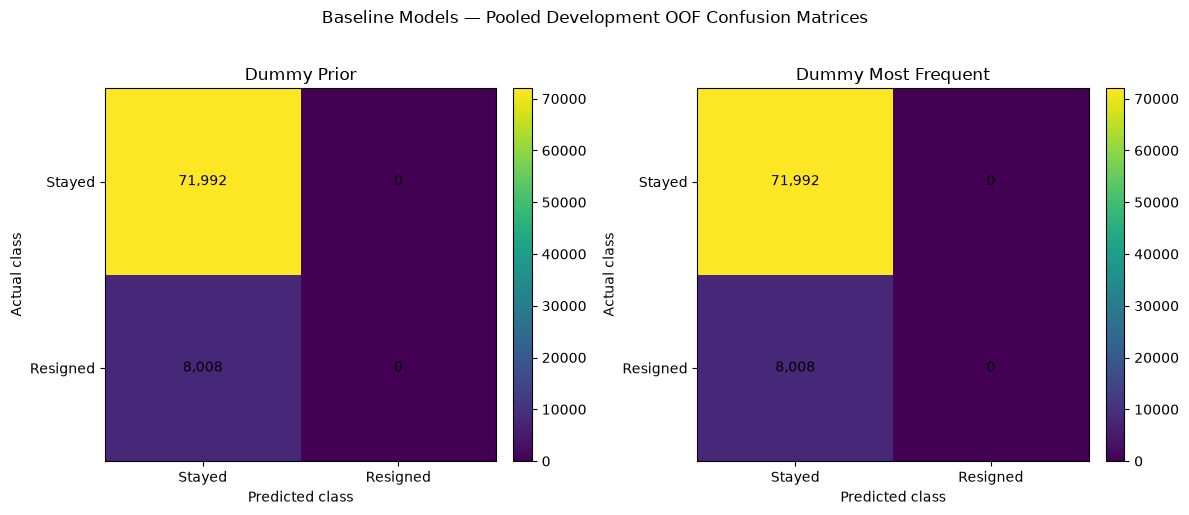

In [18]:
model_count = len(oof_predictions_by_model)
fig, axes = plt.subplots(1, model_count, figsize=(6 * model_count, 5))

if model_count == 1:
    axes = np.array([axes])
else:
    axes = np.asarray(axes).reshape(-1)

for ax, (model_name, predictions) in zip(axes, oof_predictions_by_model.items()):
    matrix = confusion_matrix(
        predictions["y_true"].astype(int),
        predictions["y_pred_0_5"].astype(int),
        labels=[0, 1],
    )
    image = ax.imshow(matrix, aspect="auto")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.set_xticks([0, 1], labels=["Stayed", "Resigned"])
    ax.set_yticks([0, 1], labels=["Stayed", "Resigned"])

    for row_index in range(2):
        for column_index in range(2):
            ax.text(
                column_index,
                row_index,
                f"{matrix[row_index, column_index]:,}",
                ha="center",
                va="center",
            )
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

fig.suptitle("Baseline Models — Pooled Development OOF Confusion Matrices", y=1.02)
fig.tight_layout()

confusion_matrix_figure_file = baseline_results_folder / "figure_01_baseline_confusion_matrices.png"
fig.savefig(confusion_matrix_figure_file, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

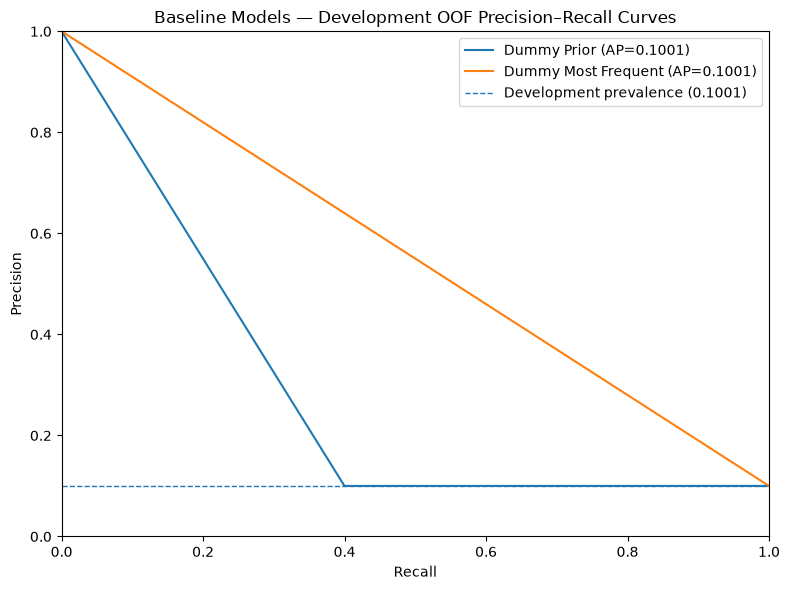

BASELINE PRECISION-RECALL CURVE: PASSED
Development positive-class prevalence: 0.1001
Saved figure: D:\Desktop\Employee_Resignation_Prediction\results\baselines\figure_02_baseline_precision_recall_curves.png


In [19]:
# ============================================================
# Plot baseline development-OOF precision-recall curves
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 6)
)


for model_name, predictions in (
    oof_predictions_by_model.items()
):

    # --------------------------------------------------------
    # Validate OOF artifact
    # --------------------------------------------------------

    validate_oof_predictions(
        predictions=predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )


    # --------------------------------------------------------
    # Precision-recall curve
    # --------------------------------------------------------

    y_true = (
        predictions["y_true"]
        .astype(int)
        .to_numpy()
    )

    y_probability = (
        predictions["y_probability"]
        .astype(float)
        .to_numpy()
    )


    precision_values, recall_values, _ = (
        precision_recall_curve(
            y_true,
            y_probability,
        )
    )


    # --------------------------------------------------------
    # Average Precision from shared metric implementation
    # --------------------------------------------------------

    model_metrics = calculate_binary_metrics(
        y_true=y_true,
        y_probability=y_probability,
    )

    model_average_precision = (
        model_metrics["average_precision"]
    )


    ax.plot(
        recall_values,
        precision_values,
        label=(
            f"{model_name} "
            f"(AP={model_average_precision:.4f})"
        ),
    )


# ============================================================
# No-skill reference line
# ============================================================

development_positive_rate = (
    development_df[target_column]
    .astype(int)
    .mean()
)


ax.axhline(
    y=development_positive_rate,
    linestyle="--",
    linewidth=1,
    label=(
        "Development prevalence "
        f"({development_positive_rate:.4f})"
    ),
)


# ============================================================
# Figure formatting
# ============================================================

ax.set_title(
    "Baseline Models — Development OOF "
    "Precision–Recall Curves"
)

ax.set_xlabel(
    "Recall"
)

ax.set_ylabel(
    "Precision"
)

ax.set_xlim(
    0,
    1,
)

ax.set_ylim(
    0,
    1,
)

ax.legend()


fig.tight_layout()


# ============================================================
# Save figure
# ============================================================

pr_curve_figure_file = (
    baseline_results_folder
    / "figure_02_baseline_precision_recall_curves.png"
)


fig.savefig(
    pr_curve_figure_file,
    dpi=160,
    bbox_inches="tight",
)


plt.show()
plt.close(fig)


# ============================================================
# Verification summary
# ============================================================

if not pr_curve_figure_file.exists():
    raise FileNotFoundError(
        "Precision-recall curve figure was not saved."
    )


print("BASELINE PRECISION-RECALL CURVE: PASSED")
print(
    "Development positive-class prevalence:",
    f"{development_positive_rate:.4f}",
)
print(
    "Saved figure:",
    pr_curve_figure_file,
)

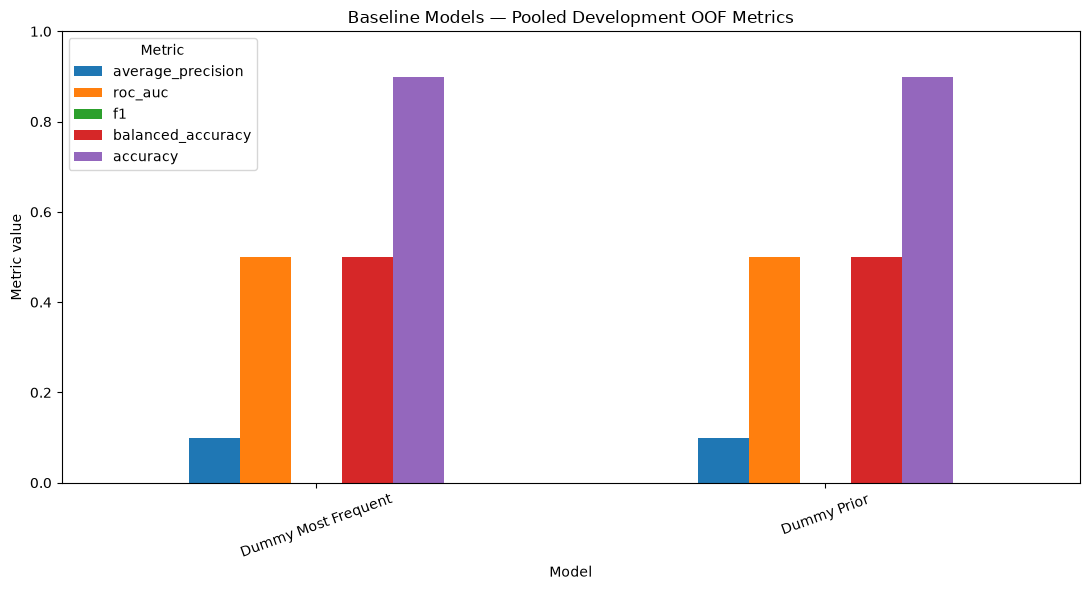

BASELINE METRIC COMPARISON FIGURE: PASSED
Metrics plotted: ['average_precision', 'roc_auc', 'f1', 'balanced_accuracy', 'accuracy']
Saved figure: D:\Desktop\Employee_Resignation_Prediction\results\baselines\figure_03_baseline_metric_comparison.png


In [20]:
# ============================================================
# Plot pooled development-OOF metric comparison
# ============================================================

selected_metric_columns = [
    "average_precision",
    "roc_auc",
    "f1",
    "balanced_accuracy",
    "accuracy",
]


# ============================================================
# Validate required metric columns
# ============================================================

missing_metric_columns = (
    set(selected_metric_columns)
    - set(baseline_summary_metrics.columns)
)

if missing_metric_columns:
    raise ValueError(
        "Baseline summary metrics are missing required columns: "
        f"{sorted(missing_metric_columns)}"
    )


if "pr_auc" in baseline_summary_metrics.columns:
    raise ValueError(
        "Obsolete metric label 'pr_auc' detected. "
        "Use 'average_precision' instead."
    )


# ============================================================
# Prepare plotting table
# ============================================================

plot_metrics = (
    baseline_summary_metrics[
        [
            "model_name",
            *selected_metric_columns,
        ]
    ]
    .set_index("model_name")
)


if plot_metrics.isna().any().any():
    raise ValueError(
        "Metric-comparison table contains missing values."
    )


# ============================================================
# Create figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)

plot_metrics.plot(
    kind="bar",
    ax=ax,
)


ax.set_title(
    "Baseline Models — Pooled Development OOF Metrics"
)

ax.set_xlabel(
    "Model"
)

ax.set_ylabel(
    "Metric value"
)

ax.set_ylim(
    0,
    1,
)

ax.tick_params(
    axis="x",
    rotation=20,
)

ax.legend(
    title="Metric"
)


fig.tight_layout()


# ============================================================
# Save figure
# ============================================================

metric_comparison_figure_file = (
    baseline_results_folder
    / "figure_03_baseline_metric_comparison.png"
)

fig.savefig(
    metric_comparison_figure_file,
    dpi=160,
    bbox_inches="tight",
)


plt.show()
plt.close(fig)


# ============================================================
# Verify saved figure
# ============================================================

if not metric_comparison_figure_file.exists():
    raise FileNotFoundError(
        "Baseline metric-comparison figure was not saved."
    )


print("BASELINE METRIC COMPARISON FIGURE: PASSED")
print(
    "Metrics plotted:",
    selected_metric_columns,
)
print(
    "Saved figure:",
    metric_comparison_figure_file,
)

## Baseline Interpretation

The mandatory Dummy models establish the minimum reference level for the project.

In [21]:
# ============================================================
# Create baseline interpretation table
# ============================================================

summary_by_model = (
    baseline_summary_metrics
    .set_index("model_name")
)


baseline_interpretation_rows = []


# ============================================================
# Dummy Prior interpretation
# ============================================================

prior_metrics = summary_by_model.loc[
    dummy_prior_model_name
]

baseline_interpretation_rows.append(
    {
        "model_name": dummy_prior_model_name,
        "role": "No-skill probability / ranking reference",
        "average_precision": prior_metrics[
            "average_precision"
        ],
        "roc_auc": prior_metrics[
            "roc_auc"
        ],
        "accuracy": prior_metrics[
            "accuracy"
        ],
        "recall": prior_metrics[
            "recall"
        ],
        "interpretation": (
            "Uses only the training-fold class prior and "
            "provides no employee-level ranking signal."
        ),
    }
)


# ============================================================
# Dummy Most Frequent interpretation
# ============================================================

most_frequent_metrics = summary_by_model.loc[
    dummy_most_frequent_model_name
]

baseline_interpretation_rows.append(
    {
        "model_name": dummy_most_frequent_model_name,
        "role": "Majority-class classification reference",
        "average_precision": most_frequent_metrics[
            "average_precision"
        ],
        "roc_auc": most_frequent_metrics[
            "roc_auc"
        ],
        "accuracy": most_frequent_metrics[
            "accuracy"
        ],
        "recall": most_frequent_metrics[
            "recall"
        ],
        "interpretation": (
            "Shows why high raw accuracy is misleading when "
            "the positive class represents only about 10% of "
            "the development data."
        ),
    }
)


# ============================================================
# Optional Logistic Regression interpretation
# ============================================================

if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    logistic_metrics = summary_by_model.loc[
        logistic_model_name
    ]

    baseline_interpretation_rows.append(
        {
            "model_name": logistic_model_name,
            "role": "Optional linear reference model",
            "average_precision": logistic_metrics[
                "average_precision"
            ],
            "roc_auc": logistic_metrics[
                "roc_auc"
            ],
            "accuracy": logistic_metrics[
                "accuracy"
            ],
            "recall": logistic_metrics[
                "recall"
            ],
            "interpretation": (
                "Provides an optional linear supervised "
                "reference using fold-local preprocessing."
            ),
        }
    )


# ============================================================
# Create interpretation table
# ============================================================

baseline_interpretation = pd.DataFrame(
    baseline_interpretation_rows
)


if len(baseline_interpretation) != len(
    oof_predictions_by_model
):
    raise ValueError(
        "Baseline interpretation table does not contain "
        "exactly one row per evaluated baseline model."
    )


if "pr_auc" in baseline_interpretation.columns:
    raise ValueError(
        "Obsolete metric label 'pr_auc' detected."
    )


# ============================================================
# Save interpretation artifact
# ============================================================

baseline_interpretation_file = (
    baseline_results_folder
    / "baseline_interpretation.csv"
)


baseline_interpretation.to_csv(
    baseline_interpretation_file,
    index=False,
    encoding="utf-8",
    lineterminator="\n",
)


# ============================================================
# Reload and validate serialized artifact
# ============================================================

baseline_interpretation_reloaded = pd.read_csv(
    baseline_interpretation_file
)


if len(
    baseline_interpretation_reloaded
) != len(
    baseline_interpretation
):
    raise ValueError(
        "Serialized baseline interpretation file has "
        "an unexpected row count."
    )


# ============================================================
# Display results
# ============================================================

print("BASELINE INTERPRETATION TABLE: PASSED")

display(
    baseline_interpretation
)

print(
    "Saved file:",
    baseline_interpretation_file,
)

BASELINE INTERPRETATION TABLE: PASSED


,model_name,role,average_precision,roc_auc,accuracy,recall,interpretation
0,Dummy Prior,No-skill probability / ranking reference,0.100085,0.499917,0.8999,0.0,Uses only the training-fold class prior and pr...
1,Dummy Most Frequent,Majority-class classification reference,0.100100,0.500000,0.8999,0.0,Shows why high raw accuracy is misleading when...


Saved file: D:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_interpretation.csv


In [22]:
# ============================================================
# Baseline output manifest path
# ============================================================

baseline_output_manifest_file = (
    baseline_results_folder
    / "baseline_output_manifest.csv"
)

print(
    "Baseline output manifest:",
    baseline_output_manifest_file,
)

Baseline output manifest: D:\Desktop\Employee_Resignation_Prediction\results\baselines\baseline_output_manifest.csv


In [23]:
# ============================================================
# Final baseline workflow validation
# ============================================================

# ------------------------------------------------------------
# Confirm frozen source artifacts have not changed
# ------------------------------------------------------------

final_raw_sha256 = sha256_file(
    raw_data_file
)

final_registry_sha256 = sha256_file(
    split_registry_file
)


if final_raw_sha256 != expected_raw_sha256:
    raise ValueError(
        "Final validation failed: raw dataset changed "
        "during baseline work."
    )

if final_registry_sha256 != expected_registry_sha256:
    raise ValueError(
        "Final validation failed: split registry changed "
        "during baseline work."
    )


# ------------------------------------------------------------
# Validate every evaluated baseline OOF artifact
# ------------------------------------------------------------

for model_name, predictions in (
    oof_predictions_by_model.items()
):

    validate_oof_predictions(
        predictions=predictions,
        split_registry=split_registry,
        source_data=raw_df,
        expected_model_name=model_name,
    )

    print(
        f"{model_name}: "
        f"OOF validation PASSED "
        f"({len(predictions):,} rows)"
    )


# ------------------------------------------------------------
# Validate expected model count
# ------------------------------------------------------------

expected_model_count = (
    3
    if RUN_OPTIONAL_LOGISTIC_REGRESSION
    else 2
)

if len(oof_predictions_by_model) != expected_model_count:
    raise ValueError(
        "Unexpected number of evaluated baseline models. "
        f"Expected {expected_model_count}, "
        f"found {len(oof_predictions_by_model)}."
    )


# ------------------------------------------------------------
# Validate final metric artifacts
# ------------------------------------------------------------

if "average_precision" not in baseline_summary_metrics.columns:
    raise ValueError(
        "Final baseline summary is missing "
        "'average_precision'."
    )

if "pr_auc" in baseline_summary_metrics.columns:
    raise ValueError(
        "Obsolete metric label 'pr_auc' remains in "
        "the baseline summary."
    )


if len(baseline_fold_metrics) != (
    expected_model_count * 5
):
    raise ValueError(
        "Unexpected number of fold-level metric rows."
    )


if len(baseline_summary_metrics) != expected_model_count:
    raise ValueError(
        "Unexpected number of pooled summary metric rows."
    )


# ------------------------------------------------------------
# Validate final output files
# ------------------------------------------------------------

required_final_outputs = [
    dummy_prior_oof_file,
    dummy_most_frequent_oof_file,
    combined_oof_file,
    baseline_fold_metrics_file,
    baseline_summary_metrics_file,
    baseline_interpretation_file,
    confusion_matrix_figure_file,
    pr_curve_figure_file,
    metric_comparison_figure_file,
    baseline_output_manifest_file,
    *confusion_matrix_files.values(),
]


if RUN_OPTIONAL_LOGISTIC_REGRESSION:

    if logistic_oof_file is None:
        raise ValueError(
            "Logistic Regression was enabled but no "
            "OOF output file was recorded."
        )

    required_final_outputs.append(
        logistic_oof_file
    )


for output_file in required_final_outputs:

    if not output_file.exists():
        raise FileNotFoundError(
            "Final validation failed: expected output "
            f"is missing:\n{output_file}"
        )

    if output_file.stat().st_size <= 0:
        raise ValueError(
            "Final validation failed: expected output "
            f"is empty:\n{output_file}"
        )


# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print()
print("FINAL BASELINE WORKFLOW VALIDATION")
print("-" * 60)
print("Raw dataset checksum: PASSED")
print("Split registry checksum: PASSED")
print(
    "Validated baseline models:",
    len(oof_predictions_by_model),
)
print(
    "Development OOF rows per model:",
    "80,000",
)
print(
    "Formal holdout used during baseline modelling:",
    "NO",
)
print(
    "Primary ranking metric:",
    "Average Precision",
)
print(
    "Baseline modelling validation: PASSED"
)

Dummy Prior: OOF validation PASSED (80,000 rows)
Dummy Most Frequent: OOF validation PASSED (80,000 rows)

FINAL BASELINE WORKFLOW VALIDATION
------------------------------------------------------------
Raw dataset checksum: PASSED
Split registry checksum: PASSED
Validated baseline models: 2
Development OOF rows per model: 80,000
Formal holdout used during baseline modelling: NO
Primary ranking metric: Average Precision
Baseline modelling validation: PASSED


## Baseline Modelling Conclusion

The shared baseline workflow is complete and reproducible.

The mandatory no-skill reference models were evaluated using only the frozen 80,000-row development partition and the exact five saved cross-validation folds. Each model produced one validated out-of-fold prediction for every development employee, while the 20,000-row formal holdout remained excluded from model development and evaluation.

The baseline results establish the minimum performance that the six advanced models must improve upon. Average Precision is used as the primary ranking metric because resignation is an imbalanced outcome, while ROC-AUC, precision, recall, F1, balanced accuracy, accuracy, and Brier score provide complementary evaluation.

All OOF prediction artifacts, fold-level metrics, pooled summary metrics, confusion matrices, figures, and output manifests were validated and saved successfully.

The project is now ready to proceed to the advanced model workflows.